# 03. CNN Model Training for Driver Drowsiness Detection
**Driver Drowsiness Detection System**  
*Training a simplified Convolutional Neural Network (CNN).*

In [1]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import time
import tensorflow as tf

from tensorflow.keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


In [5]:


from tensorflow.keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomBrightness(0.15, value_range=(0, 1))
], name="data_augmentation")

### 1. Load Preprocessed Data

In [6]:
data_path = "../dataset/preprocessed_data.npz"

if not os.path.exists(data_path):
    data_path = "dataset/preprocessed_data.npz"

data = np.load(data_path)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

print("Data loaded successfully!")

Data loaded successfully!


### 2. Check Data Shapes

Train: (59574, 80, 80, 1) (59574,)
Validation: (13015, 80, 80, 1) (13015,)
Test: (12309, 80, 80, 1) (12309,)


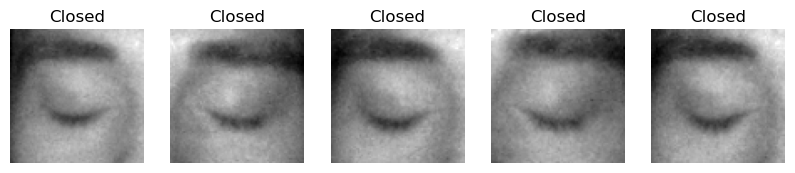

In [7]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title("Open" if y_train[i] == 1 else "Closed")
    plt.axis("off")

plt.show()

### 3. Build a CNN Model

In [8]:
model = models.Sequential([
    layers.Input(shape=(80, 80, 1)),

    # Convolution Block 1
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 4
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classification Head
    layers.Flatten(),

    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 80, 80, 64)          │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 80, 80, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 80, 80, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 40, 40, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 40, 40, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 40, 40, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 40, 40, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 20, 20, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 20, 20, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 20, 20, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 10, 10, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 10, 10, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 10, 10, 512)         │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12800)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       6,554,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │              

 Total params: 9,016,001 (34.39 MB)

 Trainable params: 9,013,057 (34.38 MB)

 Non-trainable params: 2,944 (11.50 KB)

### 4. Compile the Model

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### 5. Train the Model

In [ ]:
from tensorflow.keras import callbacks
import time

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001
)

start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr]
)

training_time = time.time() - start_time

print("Training completed!")
print("Training time:", round(training_time / 60, 2), "minutes")

### 6. Plot Training Curves

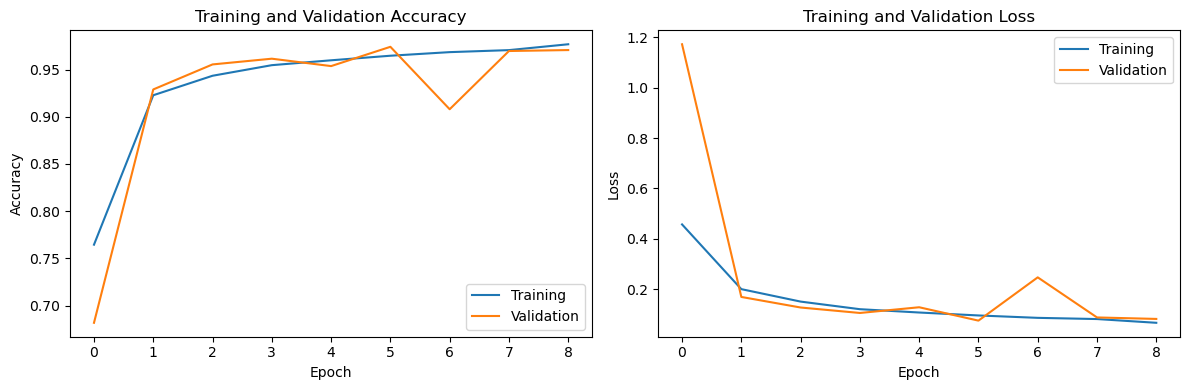

In [24]:
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 7. Evaluate on Test Set

In [25]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc*100:.2f}%")

y_pred = (model.predict(X_test) >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Closed (0)", "Open (1)"]))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 95.90%
385/385 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step

Classification Report:
              precision    recall  f1-score   support

  Closed (0)       0.95      0.96      0.96      6082
    Open (1)       0.96      0.95      0.96      6227

    accuracy                           0.96     12309
   macro avg       0.96      0.96      0.96     12309
weighted avg       0.96      0.96      0.96     12309


Confusion Matrix:
[[5858  224]
 [ 281 5946]]


In [26]:

import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Generate predictions
start_time = time.time()

y_prob = model.predict(X_test, verbose=0).ravel()

inference_time = time.time() - start_time

# Convert probabilities into classes
threshold = 0.5

y_pred = (y_prob >= threshold).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

# Overall metrics
accuracy = accuracy_score(y_test, y_pred)

# Closed-eye metrics (class 0)
closed_precision = tn / (tn + fn) if (tn + fn) > 0 else 0
closed_recall = tn / (tn + fp) if (tn + fp) > 0 else 0
closed_f1 = f1_score(y_test, y_pred, pos_label=0)

# Open-eye metrics (class 1)
open_precision = precision_score(y_test, y_pred, pos_label=1)
open_recall = recall_score(y_test, y_pred, pos_label=1)
open_f1 = f1_score(y_test, y_pred, pos_label=1)

# Additional metrics
roc_auc = roc_auc_score(y_test, y_prob)

closed_pr_auc = average_precision_score(
    1 - y_test,
    1 - y_prob
)

open_pr_auc = average_precision_score(y_test, y_prob)

# Model parameters
total_parameters = model.count_params()

# Print results
print("========== MODEL EVALUATION ==========")

print("Total Parameters:", total_parameters)

print("\nOverall Accuracy:", round(accuracy * 100, 2), "%")

print("\n--- CLOSED EYE METRICS ---")
print("Closed Precision:", round(closed_precision * 100, 2), "%")
print("Closed Recall:", round(closed_recall * 100, 2), "%")
print("Closed F1 Score:", round(closed_f1 * 100, 2), "%")

print("\n--- OPEN EYE METRICS ---")
print("Open Precision:", round(open_precision * 100, 2), "%")
print("Open Recall:", round(open_recall * 100, 2), "%")
print("Open F1 Score:", round(open_f1 * 100, 2), "%")

print("\n--- ADDITIONAL METRICS ---")
print("ROC-AUC:", round(roc_auc, 4))
print("Closed PR-AUC:", round(closed_pr_auc, 4))
print("Open PR-AUC:", round(open_pr_auc, 4))

print("\n--- CONFUSION MATRIX ---")
print(cm)

print("\nCorrect Predictions:", np.sum(y_test == y_pred))
print("Incorrect Predictions:", np.sum(y_test != y_pred))

print("\nInference Time:", round(inference_time, 3), "seconds")
print("Average Time Per Image:",
      round((inference_time / len(X_test)) * 1000, 3), "ms")

print("\n--- CLASSIFICATION REPORT ---")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Closed", "Open"]
    )
)

========== MODEL EVALUATION ==========
Total Parameters: 109825

Overall Accuracy: 95.9 %

--- CLOSED EYE METRICS ---
Closed Precision: 95.42 %
Closed Recall: 96.32 %
Closed F1 Score: 95.87 %

--- OPEN EYE METRICS ---
Open Precision: 96.37 %
Open Recall: 95.49 %
Open F1 Score: 95.93 %

--- ADDITIONAL METRICS ---
ROC-AUC: 0.9908
Closed PR-AUC: 0.9902
Open PR-AUC: 0.9917

--- CONFUSION MATRIX ---
[[5858  224]
 [ 281 5946]]

Correct Predictions: 11804
Incorrect Predictions: 505

Inference Time: 3.624 seconds
Average Time Per Image: 0.294 ms

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      Closed       0.95      0.96      0.96      6082
        Open       0.96      0.95      0.96      6227

    accuracy                           0.96     12309
   macro avg       0.96      0.96      0.96     12309
weighted avg       0.96      0.96      0.96     12309



### 8. Save the Model

In [27]:
# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save Experiment 2 model
model_path = "../models/drowsiness_cnn_experiment_2.keras"

model.save(model_path)

# Verify saved model
print("Experiment 2 model saved successfully!")
print("Path:", model_path)

print(
    "File size:",
    round(os.path.getsize(model_path) / (1024 * 1024), 2),
    "MB"
)

Experiment 2 model saved successfully!
Path: ../models/drowsiness_cnn_experiment_2.keras
File size: 1.32 MB
